# 3 · Features: Panel pro Horizont

Aus den Expertenprognosen (02) und den Tagesdaten (01) entsteht pro Horizont ein **Panel**: eine Zeile pro Serie und Ursprung mit

- Ziel `y` (gemessene RV) und, falls bekannt, `true_var`
- Mittelwert und 21 Quantile jedes Experten im Pool
- den Features für das Gate (alle am Ursprung $t$ bekannt, kein Leakage)
- `scale` = RV-Niveau der letzten 22 Tage (Normierung des Pinball-Loss, kein Feature)

Die Features werden hier **nicht** standardisiert. Mittelwert und Streuung schätzt 04 pro Fold nur auf den Trainingszeilen, sonst würde Information aus der Testperiode einfliessen.

### Feature-Gruppen

| Gruppe | Features | Idee |
|---|---|---|
| `market` | `logrv_dev`, `trend`, `level_rel`, `volvol`, `ret1`, `ret5` | Marktzustand aus der RV-Historie |
| `disagree` | $\ln\hat\mu_m - \frac1M\sum_j \ln\hat\mu_j$ | wie stark ein Experte vom Pool abweicht |
| `recent` | $\ln L_m - \frac1M\sum_j \ln L_j$, $L$ = EWMA-QLIKE, um $h$ verschoben | wer war zuletzt gut? (mehrere Halbwertszeiten) |
| `calendar` | `weekend` | Zieldatum ist Samstag/Sonntag (Krypto-Vola am Wochenende tiefer) |
| `exo` | alle Spalten `exo_*` | externe Information (DVOL, Volumen, Funding, synthetisches Signal) |
| `series` | One-Hot der Serie | Bias pro Coin (standardmässig aus) |

### Änderungen gegenüber `01_kombination` (alt)

- **`level` → `level_rel`:** $\ln RV^{(22)}_t$ minus Mittel der log-RV der letzten 250 Tage. Das absolute Niveau ist nicht stationär (2021 anders als 2026) und verrät bei einem gemeinsamen Gate, um welchen Coin es geht.
- **Keine redundanten Spalten:** `disagree_*` und `recent_*` summieren sich über die Experten zu 0. Ein Experte wird deshalb weggelassen (`DROP_REDUNDANT`).
- **Mehrere Halbwertszeiten** für `recent` (10 und 60 Prognosen): Der QLIKE hat schwere Ausreisser, 10 allein ist sehr verrauscht.
- **Neue Gruppen** `calendar`, `exo` und `series`.

Mit `LEGACY = True` entstehen exakt die alten 14 Features (zum Reproduzieren).

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATASET = "binance"        # Name aus 01_daten.ipynb, z.B. "binance" oder "syn_regime_signal_s0"

DATA_DIR, RESULTS_DIR = Path("data"), Path("results")
INFO = json.loads((DATA_DIR / f"{DATASET}.json").read_text())
DAILY_DIR, FORECAST_DIR = Path(INFO["daily_dir"]), Path(INFO["forecast_dir"])
SIDS = INFO["sids"]
SYNTHETIC = INFO["info"]["source"] == "synthetic"
print(f"Datensatz {DATASET}: {len(SIDS)} Serien {SIDS}")

QUANTILES = [0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5,
             0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99]   # = native Chronos-2-Quantile
QCOLS = [f"q{q:.2f}" for q in QUANTILES]
_LV = np.asarray(QUANTILES)

POOL = ["Chronos-2-full", "TimesFM-2.5", "HAR", "GARCH"] if not SYNTHETIC else ["HAR", "GARCH", "RW"]

LEGACY = False                  # True: exakt die Features aus 01_kombination.ipynb
GROUPS = ["market", "disagree", "recent", "calendar", "exo"]    # + "series" für einen Bias pro Serie
HALFLIVES = [10, 60]            # Halbwertszeiten (in Prognosen) der recent-Features
MIN_PERIODS = 5
LEVEL = "relative"              # "relative" oder "absolute" (alt)
LEVEL_WINDOW = 250
DROP_REDUNDANT = True

if LEGACY:
    GROUPS, HALFLIVES, LEVEL, DROP_REDUNDANT = ["market", "disagree", "recent"], [10], "absolute", False

PANEL_DIR = RESULTS_DIR / "panels" / DATASET

Datensatz binance: 3 Serien ['BTCUSDT', 'ETHUSDT', 'SOLUSDT']


## Prognosen laden, jüngste Fehler

$L_m$ ist der exponentiell gewichtete QLIKE-Fehler von Experte $m$. Für Horizont $h$ wird um $h$ Ursprünge verschoben: Am Ursprung $t$ ist das Ziel der Prognose von $t-h$ gerade bekannt geworden, spätere noch nicht.

In [2]:
def qlike(y, f):
    r = y / f
    return r - np.log(r) - 1


fc = pd.concat([pd.read_parquet(FORECAST_DIR / f"{sid}__{m}.parquet").drop(columns="split", errors="ignore")
                for sid in SIDS for m in POOL], ignore_index=True)
fc = fc.sort_values(["sid", "h", "model", "origin"]).reset_index(drop=True)
fc["qlike"] = qlike(fc["y"].to_numpy(), fc["mean"].to_numpy())

for hl in HALFLIVES:
    fc[f"recent{hl}"] = np.nan
    for h, g in fc.groupby("h"):
        fc.loc[g.index, f"recent{hl}"] = g.groupby(["sid", "model"])["qlike"].transform(
            lambda x: x.shift(h).ewm(halflife=hl, min_periods=MIN_PERIODS).mean())

print(f"{len(fc):,} Prognosen, Pool: {POOL}")

44,368 Prognosen, Pool: ['Chronos-2-full', 'TimesFM-2.5', 'HAR', 'GARCH']


## Marktzustand aus den Tagesdaten

Notation: $RV^{(k)}$ = gleitender Mittelwert der RV über $k$ Tage.

| Feature | Formel | Interpretation |
|---|---|---|
| `logrv_dev` | $\ln RV_t - \ln RV^{(22)}_t$ | > 0: heute unruhiger als üblich |
| `trend` | $\ln RV^{(5)}_t - \ln RV^{(22)}_t$ | > 0: Vola steigt |
| `level_rel` | $\ln RV^{(22)}_t - \overline{\ln RV}^{(250)}_t$ | Vola-Phase relativ zum langfristigen Niveau der Serie |
| `volvol` | Std.-Abw. von $\ln RV$ über 22 Tage | RV springt stark, schwer vorherzusagen |
| `ret1` | $ret_t / \sqrt{RV^{(22)}_t}$ | Schock gestern |
| `ret5` | $\sum_5 ret / \sqrt{5\,RV^{(22)}_t}$ | anhaltende Bewegung |

In [3]:
def market_features(d):
    rv, ret = d["rv"], d["ret"]
    lrv, rv22 = np.log(rv), rv.rolling(22).mean()
    f = pd.DataFrame({"logrv_dev": lrv - np.log(rv22), "trend": np.log(rv.rolling(5).mean()) - np.log(rv22)})
    if LEVEL == "absolute":
        f["level"] = np.log(rv22)
    else:
        f["level_rel"] = np.log(rv22) - lrv.rolling(LEVEL_WINDOW, min_periods=60).mean()
    f["volvol"] = lrv.rolling(22).std()
    f["ret1"] = ret / np.sqrt(rv22)
    f["ret5"] = ret.rolling(5).sum() / np.sqrt(5 * rv22)
    return f


parts = []
for sid in SIDS:
    d = pd.read_parquet(DAILY_DIR / f"{sid}_daily.parquet")
    f = market_features(d)
    f["scale"] = d["rv"].rolling(22).mean()
    for c in d.columns:
        if c.startswith("exo_"):
            f[c] = d[c]
    f.index = pd.MultiIndex.from_arrays([np.repeat(sid, len(f)), f.index], names=["sid", "origin"])
    parts.append(f)
daily_feat = pd.concat(parts)
MARKET = [c for c in daily_feat.columns if c != "scale" and not c.startswith("exo_")]
EXO = [c for c in daily_feat.columns if c.startswith("exo_")]

true_var = None
if SYNTHETIC:
    true_var = pd.concat([pd.read_parquet(DAILY_DIR / f"{sid}_daily.parquet")[["true_var", "regime"]]
                          .assign(sid=sid) for sid in SIDS]).rename_axis("target_date").reset_index()

## Panel bauen und speichern

Gespeichert wird pro Horizont eine Tabelle `h<h>.parquet` mit den Spalten `mean|<Modell>`, `q0.05|<Modell>`, `recent|<Modell>` (roher EWMA-QLIKE, für die Baseline „Inverse jüngste Fehler“) und `x|<Feature>`. Dazu kommt `panel.json` mit Pool und Feature-Gruppen.

In [4]:
def build_panel(h):
    sub = fc[fc["h"] == h]
    rec = [f"recent{hl}" for hl in HALFLIVES]
    wide = sub.set_index(["sid", "origin", "model"])[["y", "target_date", "mean"] + rec + QCOLS].unstack("model")
    mean = wide["mean"][POOL].to_numpy()
    Q = np.stack([wide[c][POOL].to_numpy() for c in QCOLS], axis=-1)
    ok = np.isfinite(mean).all(1) & np.isfinite(Q).all((1, 2))     # nur Zeilen, für die alle Experten prognostizieren
    wide, mean, Q = wide[ok], mean[ok], Q[ok]

    meta = pd.DataFrame({"y": wide["y"][POOL[0]].to_numpy(),
                         "target_date": pd.to_datetime(wide["target_date"][POOL[0]].to_numpy())}, index=wide.index)
    meta = meta.join(daily_feat).reset_index()
    if true_var is not None:
        meta = meta.merge(true_var, on=["sid", "target_date"], how="left")

    keep = POOL[:-1] if DROP_REDUNDANT else POOL
    groups, X = {"market": MARKET}, {c: meta[c].to_numpy() for c in MARKET}
    logm = np.log(mean)
    groups["disagree"] = [f"disagree_{m}" for m in keep]
    for j, m in enumerate(keep):
        X[f"disagree_{m}"] = logm[:, j] - logm.mean(1)
    groups["recent"] = []
    for hl in HALFLIVES:
        lrec = np.log(wide[f"recent{hl}"][POOL].to_numpy())
        for j, m in enumerate(keep):
            name = f"recent_{m}" if len(HALFLIVES) == 1 else f"recent{hl}_{m}"
            groups["recent"].append(name)
            X[name] = lrec[:, j] - lrec.mean(1)
    groups["calendar"] = ["weekend"]
    X["weekend"] = (meta["target_date"].dt.dayofweek >= 5).astype(float).to_numpy()
    groups["exo"] = EXO
    X.update({c: meta[c].to_numpy() for c in EXO})
    groups["series"] = [f"series_{s}" for s in SIDS]
    X.update({f"series_{s}": (meta["sid"] == s).astype(float).to_numpy() for s in SIDS})
    groups = {g: groups[g] for g in GROUPS if groups.get(g)}

    out = meta[["sid", "origin", "target_date", "y", "scale"] + [c for c in ["true_var", "regime"] if c in meta]].copy()
    out.insert(1, "h", h)
    cols = {f"mean|{m}": mean[:, j] for j, m in enumerate(POOL)}
    cols.update({f"{qc}|{m}": Q[:, j, k] for j, m in enumerate(POOL) for k, qc in enumerate(QCOLS)})
    cols.update({f"recent|{m}": wide[rec[0]][m].to_numpy() for m in POOL})
    cols.update({f"x|{c}": X[c] for g in groups.values() for c in g})
    return pd.concat([out, pd.DataFrame(cols)], axis=1), groups


PANEL_DIR.mkdir(parents=True, exist_ok=True)
panels = {}
for h in sorted(fc["h"].unique()):
    panels[h], GROUP_MAP = build_panel(h)
    panels[h].to_parquet(PANEL_DIR / f"h{h}.parquet")
(PANEL_DIR / "panel.json").write_text(json.dumps(
    {"pool": POOL, "groups": GROUP_MAP, "horizons": [int(h) for h in panels],
     "config": {"legacy": LEGACY, "halflives": HALFLIVES, "level": LEVEL, "drop_redundant": DROP_REDUNDANT}},
    indent=2))

FEATS = [c for g in GROUP_MAP.values() for c in g]
print(f"{len(FEATS)} Features in {len(GROUP_MAP)} Gruppen:")
for g, cs in GROUP_MAP.items():
    print(f"  {g:<9} {cs}")
for h, P in panels.items():
    print(f"h={h}: {len(P):,} Zeilen, {P['target_date'].min().date()} bis {P['target_date'].max().date()}")

16 Features in 4 Gruppen:
  market    ['logrv_dev', 'trend', 'level_rel', 'volvol', 'ret1', 'ret5']
  disagree  ['disagree_Chronos-2-full', 'disagree_TimesFM-2.5', 'disagree_HAR']
  recent    ['recent10_Chronos-2-full', 'recent10_TimesFM-2.5', 'recent10_HAR', 'recent60_Chronos-2-full', 'recent60_TimesFM-2.5', 'recent60_HAR']
  calendar  ['weekend']
h=1: 5,546 Zeilen, 2021-05-22 bis 2026-08-27
h=5: 5,546 Zeilen, 2021-05-26 bis 2026-08-31


/var/folders/fc/r822p1_s5v5_mswzrz420sj00000gn/T/ipykernel_48295/4102937294.py:30: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  X["weekend"] = (meta["target_date"].dt.dayofweek >= 5).astype(float).to_numpy()
/var/folders/fc/r822p1_s5v5_mswzrz420sj00000gn/T/ipykernel_48295/4102937294.py:30: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  X["weekend"] = (meta["target_date"].dt.dayofweek >= 5).astype(float).to_numpy()


## Kontrolle: Verteilung und Korrelation der Features

Stark korrelierte Features tragen dieselbe Information. Für das lineare Gate ist das kein Fehler (L2 verteilt das Gewicht), es macht die Koeffizienten aber schwerer interpretierbar.

,count,mean,std,min,max
logrv_dev,5546.0,-0.284,0.772,-3.091,2.877
trend,5546.0,-0.126,0.510,-2.250,1.370
level_rel,5546.0,0.169,0.576,-1.767,2.092
volvol,5546.0,0.708,0.199,0.290,1.539
ret1,5546.0,0.010,1.006,-5.171,7.564
ret5,5546.0,0.028,1.010,-3.917,5.694
disagree_Chronos-2-full,5546.0,-0.052,0.235,-1.049,1.836
disagree_TimesFM-2.5,5546.0,-0.173,0.185,-0.895,0.663
disagree_HAR,5546.0,0.032,0.210,-0.619,1.233
recent10_Chronos-2-full,5531.0,-0.163,0.169,-0.744,0.403


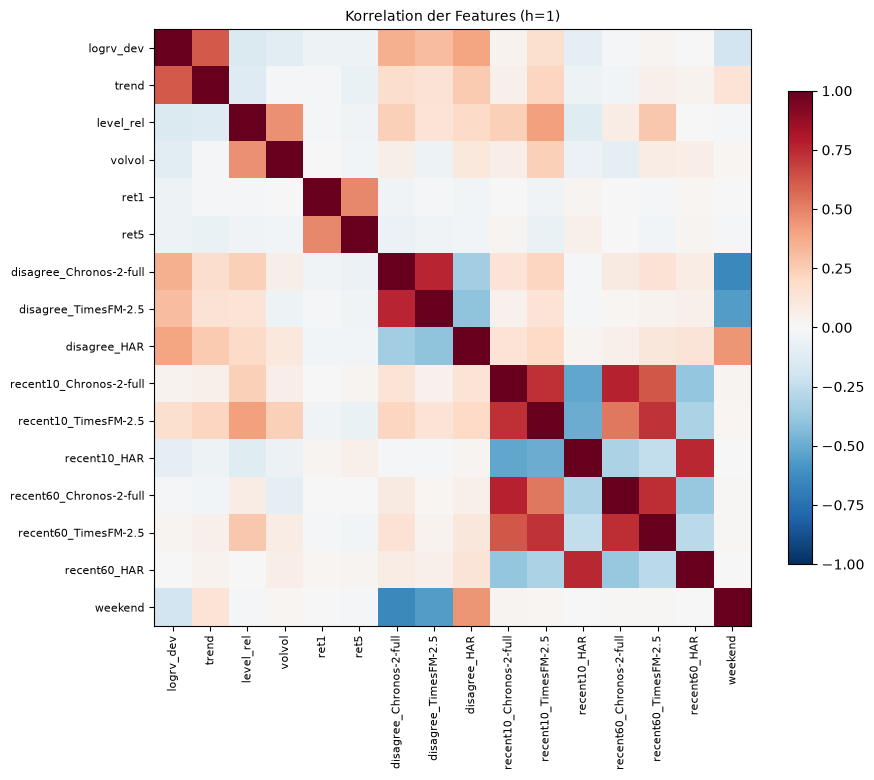

In [5]:
X1 = panels[min(panels)][[f"x|{c}" for c in FEATS]]
X1.columns = FEATS
display(X1.describe().T[["count", "mean", "std", "min", "max"]].round(3))

C = X1.corr()
fig, ax = plt.subplots(figsize=(0.45 * len(FEATS) + 2, 0.45 * len(FEATS) + 1))
im = ax.imshow(C, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(FEATS)), FEATS, rotation=90, fontsize=8)
ax.set_yticks(range(len(FEATS)), FEATS, fontsize=8)
plt.colorbar(im, ax=ax, shrink=0.7)
ax.set_title(f"Korrelation der Features (h={min(panels)})", fontsize=10)
plt.tight_layout()
plt.show()